# Financial sentiment and named entities, from the raw text

**Questions explored**
1. What makes financial wire text different from the text generic NLP tools are built for?
2. How well do word-based sentiment methods read financial news? Rather than eyeballing scores, earnings articles give us **free ground truth**: Reuters prints lines such as `Shr 1.20 dlrs vs 1.05 dlrs`, so the actual direction of earnings per share can be parsed and compared with what each method predicts.
3. Which entities can be extracted reliably, and what does it take to link them to companies?

In [1]:
# %pip install nltk transformers torch spacy && python -m spacy download en_core_web_sm

# Libraries and setup

In [2]:
import re
from collections import Counter, defaultdict
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from bs4 import BeautifulSoup

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

DATA_PATH = Path("classification_V1/reuters21578")
RANDOM_STATE = 42
pd.set_option("display.max_colwidth", 100)

## Parsing the SGML files

In [3]:
def parse_sgm_file(filepath):
    with open(filepath, "r", encoding="latin-1") as f:
        soup = BeautifulSoup(f.read(), "html.parser")
    articles = []
    for r in soup.find_all("reuters"):
        title = r.title.text.strip() if r.title else ""
        body = r.body.text.strip() if r.body else ""
        articles.append({
            "id": r.get("newid"),
            "date": r.date.text.strip() if r.date else None,
            "title": title, "body": body, "text": f"{title}. {body}",
            "topics": [d.text for d in r.topics.find_all("d")] if r.topics else [],
        })
    return articles

rows = []
for file in sorted(DATA_PATH.glob("*.sgm")):
    rows.extend(parse_sgm_file(file))
df = pd.DataFrame(rows)
df = df[df["body"].str.len() > 0].reset_index(drop=True)
df["date"] = pd.to_datetime(df["date"].str.split(".").str[0], format="%d-%b-%Y %H:%M:%S", errors="coerce")
print(f"{len(df):,} articles with a body, {df['date'].min():%d %b %Y} to {df['date'].max():%d %b %Y}")

19,043 articles with a body, 26 Feb 1987 to 20 Oct 1987


# 1. What financial wire text looks like

Three properties matter for every downstream tool: the abbreviations, the share of numbers, and the
capitalisation of headlines.

In [4]:
tokens = df["text"].str.lower().str.findall(r"[a-z]+").explode()
token_counts = tokens.value_counts()
abbrev = ["mln", "dlrs", "pct", "vs", "shr", "cts", "qtr", "revs", "stg", "bln", "avg", "shrs", "oper", "div"]
print("Most frequent Reuters abbreviations (occurrences in the corpus):")
token_counts.reindex(abbrev).sort_values(ascending=False).to_frame("occurrences")

Most frequent Reuters abbreviations (occurrences in the corpus):


,occurrences
text,
mln,26386
dlrs,20837
pct,17626
vs,14586
cts,8901
shr,4104
qtr,2593
revs,2368
stg,1723


In [5]:
def digit_share(text):
    chars = [c for c in text if not c.isspace()]
    return sum(c.isdigit() for c in chars) / max(1, len(chars))

df["digit_share"] = df["body"].apply(digit_share)
df["title_all_caps"] = df["title"].apply(lambda t: t.isupper())
main_topic = df["topics"].apply(lambda ts: next((t for t in ["earn", "acq", "money-fx", "interest", "crude", "grain", "trade"] if t in ts), "other"))
summary = df.assign(topic=main_topic).groupby("topic").agg(
    articles=("id", "size"),
    median_words=("body", lambda s: int(s.str.split().str.len().median())),
    digit_share=("digit_share", "mean"),
)
summary["digit_share"] = summary["digit_share"].map("{:.1%}".format)
print(f"Headlines written entirely in capitals: {df['title_all_caps'].mean():.1%}")
summary.sort_values("articles", ascending=False)

Headlines written entirely in capitals: 99.9%


,articles,median_words,digit_share
topic,,,
other,10626,95,3.6%
earn,3776,49,18.5%
acq,2192,88,2.2%
money-fx,683,129,2.6%
grain,567,121,5.2%
crude,526,180,2.6%
trade,437,210,2.3%
interest,236,99,4.0%


Earnings articles are short and dense with figures: they are tables in prose form. And almost every headline is
upper-case, which removes the capitalisation cue that NER models rely on to spot names (tested in section 4).

# 2. Ground truth for financial sentiment: parsing earnings per share

An earnings article states the current and prior earnings per share (`Shr ... vs ...`). Their comparison is an
objective label: earnings went **up** or **down**. Details the parser must handle, all from the real data:
- units in dollars or cents (`Shr 34 cts vs 1.19 dlrs`), sometimes only on one side;
- losses (`Shr loss 22 cts vs loss 18 cts`, `Shr loss two cts vs profit seven cts`);
- numbers written as words (`Shr one dlr vs 73 cts`).

In [6]:
WORD_NUMBERS = {w: i for i, w in enumerate(
    "zero one two three four five six seven eight nine ten eleven twelve thirteen fourteen "
    "fifteen sixteen seventeen eighteen nineteen twenty".split())}
NUMBER = r"(?:[\d,]*\.?\d+|" + "|".join(WORD_NUMBERS) + r")"
SIDE = r"(loss\s+)?(?:profit\s+)?(" + NUMBER + r")\s*(dlrs?|cts?)?"
SHR_LINE = re.compile(r"\bshr\s+" + SIDE + r"\s+vs\.?\s+" + SIDE, re.IGNORECASE)

def to_dollars(is_loss, number, unit, other_unit):
    value = WORD_NUMBERS.get(number.lower())
    value = float(value) if value is not None else float(number.replace(",", ""))
    if (unit or other_unit or "dlrs").lower().startswith("ct"):
        value /= 100
    return -value if is_loss else value

def eps_direction(text):
    m = SHR_LINE.search(text)
    if not m:
        return None
    loss1, n1, u1, loss2, n2, u2 = m.groups()
    current, prior = to_dollars(loss1, n1, u1, u2), to_dollars(loss2, n2, u2, u1)
    return "up" if current > prior else "down" if current < prior else "flat"

for example in ["Shr 34 cts vs 1.19 dlrs", "Shr loss 22 cts vs loss 18 cts",
                "Shr loss two cts vs profit seven cts", "Shr one dlr vs 73 cts"]:
    print(f"{example:40s} -> {eps_direction(example)}")

Shr 34 cts vs 1.19 dlrs                  -> down
Shr loss 22 cts vs loss 18 cts           -> down
Shr loss two cts vs profit seven cts     -> down
Shr one dlr vs 73 cts                    -> up


In [7]:
earn = df[df["topics"].apply(lambda ts: "earn" in ts)].copy()
earn["eps"] = earn["text"].apply(eps_direction)
print(earn["eps"].value_counts(dropna=False).rename(index={None: "no Shr line"}).to_string())
labeled = earn[earn["eps"].isin(["up", "down"])].reset_index(drop=True)
majority = labeled["eps"].value_counts(normalize=True).max()
print(f"\n{len(labeled):,} labeled earnings articles; majority-class baseline ('always up'): {majority:.1%}")

eps
no Shr line    1738
up             1209
down            753
flat             76

1,962 labeled earnings articles; majority-class baseline ('always up'): 61.6%


Articles without a `Shr` line are earnings *previews*, dividend notices or narrative stories: they are left out rather than guessed. 
Any sentiment method must now beat the **majority baseline** above to be worth anything.

# 3. Reading sentiment from words

## 3a. A generic sentiment model: VADER (optional)

VADER is a lexicon and rule system built for social media. 
Its compound score is mapped to up/down with the usual ±0.05 neutral band.

In [8]:
import nltk
from nltk.sentiment import SentimentIntensityAnalyzer
nltk.download('vader_lexicon', quiet=True)

True

In [9]:
TARGET_TOPICS = ['money-fx', 'ship', 'interest', 'acq', 'earn']
def select_target_topic(topics):
    selected = [t for t in topics if t in TARGET_TOPICS]
    return selected[0] if len(selected) == 1 else None

copy_df = df.copy()
copy_df['label'] = copy_df['topics'].apply(select_target_topic)
copy_df = copy_df.dropna(subset=['label'])

In [10]:
sia = SentimentIntensityAnalyzer()

# Compute sentiment scores
copy_df['sentiment'] = copy_df['text'].apply(lambda x: sia.polarity_scores(x)['compound'])

# Classify sentiment as positive, neutral, or negative
def sentiment_label(score):
    if score > 0.05:
        return 'positive'
    elif score < -0.05:
        return 'negative'
    else:
        return 'neutral'
copy_df['sentiment_label'] = copy_df['sentiment'].apply(sentiment_label)

sentiment_counts = copy_df['sentiment_label'].value_counts(normalize=True)
print("Overall sentiment distribution:\n", sentiment_counts)

Overall sentiment distribution:
 sentiment_label
positive    0.621462
negative    0.221664
neutral     0.156874
Name: proportion, dtype: float64


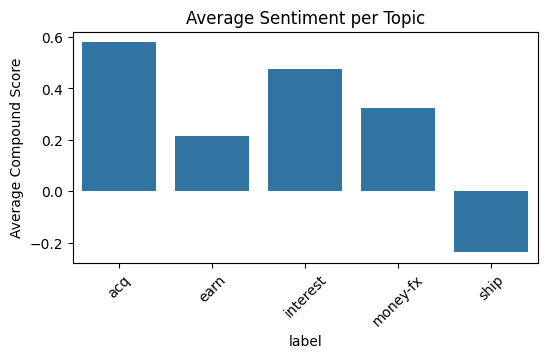

In [11]:
import seaborn as sns
sentiment_per_topic = copy_df.groupby('label')['sentiment'].mean()
plt.figure(figsize=(6,3))
sns.barplot(x=sentiment_per_topic.index, y=sentiment_per_topic.values)
plt.title("Average Sentiment per Topic")
plt.ylabel("Average Compound Score")
plt.xticks(rotation=45)
plt.show()

In [12]:
vader = SentimentIntensityAnalyzer()

labeled["vader"] = labeled["text"].apply(lambda t: vader.polarity_scores(t)["compound"])
vader_pred = np.select([labeled["vader"] > 0.05, labeled["vader"] < -0.05], ["up", "down"], "neutral")
print(f"VADER: neutral on {np.mean(vader_pred == 'neutral'):.1%} of articles, accuracy where it commits: {np.mean(vader_pred[vader_pred != 'neutral'] == labeled['eps'][vader_pred != 'neutral']):.1%}")

VADER: neutral on 32.8% of articles, accuracy where it commits: 56.1%


## 3b. A finance word list

Domain lexicons such as Loughran–McDonald were built because general sentiment dictionaries misread finance
("liability", "tax", "cost" are negative in general English but neutral in a filing). The list below is a small,
hand-written illustration in that spirit, not the real dictionary.

In [13]:
POSITIVE = set("rose rise rises risen gain gains gained increase increased increases higher up record profit profits "
               "improved improvement strong stronger growth surge surged beat exceeded recovery boost".split())
NEGATIVE = set("fell fall falls drop dropped decline declined declines lower down loss losses weak weaker deficit "
               "writedown writeoff charge charges decrease decreased reduced slump plunged poor worse".split())

def lexicon_tone(text):
    words = re.findall(r"[a-z]+", text.lower())
    pos, neg = sum(w in POSITIVE for w in words), sum(w in NEGATIVE for w in words)
    return pos, neg

labeled[["pos_words", "neg_words"]] = labeled["text"].apply(lambda t: pd.Series(lexicon_tone(t)))
lex_pred = np.select([labeled["pos_words"] > labeled["neg_words"], labeled["pos_words"] < labeled["neg_words"]],
                     ["up", "down"], "no signal")
committed = lex_pred != "no signal"
print(f"no signal (tie or no sentiment words): {np.mean(~committed):.1%} of articles")
print(f"accuracy where it commits: {np.mean(lex_pred[committed] == labeled['eps'][committed]):.1%}   (majority baseline {majority:.1%})")

no signal (tie or no sentiment words): 51.9% of articles
accuracy where it commits: 53.6%   (majority baseline 61.6%)


The word list finds nothing to say (or a tie) on about half of the articles, and where it does commit it is
**below the majority baseline**: worse than always answering "up". Looking at which words occur shows why:

In [14]:
words_by_direction = {}
for direction in ["up", "down"]:
    subset = labeled[labeled["eps"] == direction]["text"].str.lower()
    words_by_direction[f"share of '{direction}' articles"] = {w: subset.str.contains(rf"\b{w}\b").mean() for w in ["profit", "loss", "net", "rose", "fell", "record"]}
pd.DataFrame(words_by_direction).map("{:.0%}".format)

,share of 'up' articles,share of 'down' articles
profit,22%,35%
loss,40%,53%
net,100%,100%
rose,0%,0%
fell,0%,0%
record,3%,3%


In [15]:
example = labeled[(labeled["eps"] == "up") & labeled["text"].str.contains(r"Shr loss", case=False)].iloc[0]
print(f"EPS direction: {example['eps']}   lexicon: +{example['pos_words']} / -{example['neg_words']}\n")
print(example["text"][:350])

EPS direction: up   lexicon: +0 / -8

<PAGE PETROLEUM LTD> YEAR LOSS. Shr loss 1.98 dlrs vs loss 5.24 dlrs
    Net loss 23.3 mln vs loss 44.8 mln
    Revs 13.6 mln vs 29.6 mln
    Note: 1986 net includes nine mln dlr extraordinary loss for
oil and gas writedowns and unrealized foreign exchange losses
vs yr-ago loss of 32.5 mln dlrs.
 Reuter



- "net" is in every article, "rose" and "fell" in none: the direction is never stated in words, only by the numbers.
- "profit" and "loss" are **row labels**, not opinions. A narrowing loss is good news written with the word "loss" eight times (Page Petroleum above: loss per share cut from 5.24 to 1.98 dollars).
- They lean the "wrong" way: "profit" appears in *more* down articles than up ones, because tables write "Shr profit 5 cts vs profit 30 cts" when profits shrink.

## 3c. Can a model learn it from the words?

A lexicon is a fixed guess, a classifier can learn which tokens matter. Same labels, TF-IDF + logistic regression, 5-fold cross-validation, with the `Shr` line *removed* so the model cannot read the answer directly.

In [16]:
def without_shr_line(text):
    return re.sub(r"(?i)\bshr\b[^\n]*", " ", text)

X_text = labeled["text"].apply(without_shr_line)
y = (labeled["eps"] == "up").astype(int)
clf = LogisticRegression(max_iter=2000, class_weight="balanced")
for name, vec in [("words only", TfidfVectorizer(token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z]+\b", ngram_range=(1, 2), min_df=2)),
                  ("words + numbers", TfidfVectorizer(ngram_range=(1, 2), min_df=2))]:
    scores = cross_val_score(clf, vec.fit_transform(X_text), y, cv=5, scoring="accuracy")
    print(f"{name:16s} accuracy {scores.mean():.1%} ± {scores.std():.1%}")

words only       accuracy 65.1% ± 1.4%
words + numbers  accuracy 66.3% ± 2.6%


A trained model does a little better than the majority baseline (~65% vs 61.6%), and adding numbers as tokens barely helps: a bag of words cannot express "the first number on this line is larger than the second". 
The remaining signal it finds is indirect (words like "extraordinary", "writedowns" or "discontinued" in the notes correlate with bad years). 
The information is in a **comparison between two numbers**, not in any token, which the parser reads exactly.

**Lesson:** on structured financial text, a 10-line parser is the best "sentiment model" available, and it is exact and explainable. Learned sentiment models earn their place on narrative text, where the tone is in the words.

## 3d. FinBERT on narrative sentences (optional)

FinBERT (`ProsusAI/finbert`) is BERT trained further on financial text and fine-tuned on sentences labeled from an investor's point of view. 
The sentences below are chosen where general English and financial meaning diverge.

In [17]:
from transformers import pipeline

finbert = pipeline("sentiment-analysis", model="ProsusAI/finbert")
sentences = [
    "The company cut its debt by half and reduced its liabilities.",
    "The central bank announced a cut in its discount rate.",
    "The company narrowed its quarterly loss to two cts a share from 18 cts.",
    "Net profit rose 40 pct, beating analysts' forecasts.",
    "The firm swung to a loss and suspended its dividend.",
    "Shares were unchanged in quiet trading.",
]
rows = [{"sentence": s, "finbert": finbert(s)[0]["label"], "word list": "up" if lexicon_tone(s)[0] > lexicon_tone(s)[1] else "down" if lexicon_tone(s)[0] < lexicon_tone(s)[1] else "none"}
        for s in sentences]
if "vader" in globals():
    for r in rows:
        r["vader"] = round(vader.polarity_scores(r["sentence"])["compound"], 2)
pd.DataFrame(rows)

Device set to use mps:0


,sentence,finbert,word list,vader
0,The company cut its debt by half and reduced its liabilities.,positive,down,-0.66
1,The central bank announced a cut in its discount rate.,negative,none,-0.27
2,The company narrowed its quarterly loss to two cts a share from 18 cts.,positive,down,-0.03
3,"Net profit rose 40 pct, beating analysts' forecasts.",positive,up,-0.03
4,The firm swung to a loss and suspended its dividend.,negative,down,-0.66
5,Shares were unchanged in quiet trading.,neutral,none,0.30


In [18]:
# FinBERT on the earnings articles: same ground truth as above.
sample = labeled.sample(300, random_state=RANDOM_STATE)
fin_label = sample["text"].str[:512].apply(lambda t: finbert(t)[0]["label"])
pred = fin_label.map({"positive": "up", "negative": "down"})
print(f"FinBERT neutral on {pred.isna().mean():.1%}; accuracy where it commits: {(pred.dropna() == sample['eps'][pred.notna()]).mean():.1%}")

FinBERT neutral on 26.0%; accuracy where it commits: 41.0%


looking at the results, the table seems to really show that FinBERT is better at capturing the sentiment of financial text compared to generic sentiment models. 
It can understand the context and nuances of financial language, which is crucial for accurate sentiment analysis in this domain.
Otherwise, for our mesured test, performed only on algorithm labelled sentences, the results are not as good, but it could also be due to the fact that our definition of "up" and "down" based on the number only is not capturing the full sentiment of the sentences (e.g., 8$ vs 10$ is "down" but the sentence could be positive if the company was expected to lose money).

# 4. Named entities

## 4a. What regular expressions can extract reliably

Some financial entities follow fixed conventions in this corpus, so patterns are precise and transparent:
- **TICKER**: Reuters editors put exchange tickers in angle brackets after the company name: `CHRYSLER CORP <C>`;
- **MONEY**: an amount, an optional scale and a currency: `1.4 billion dlrs`, `100 mln stg`;
- **PERCENT**: `12 pct`.

In [19]:
TICKER = re.compile(r"<([A-Z][A-Z0-9.]{0,5})>")
# The amount must use valid thousands grouping (1,234,567): see the data-quality check below
AMOUNT = r"(?<![\d,.])((?:\d{1,3}(?:,\d{3})+|\d+)(?:\.\d+)?)(?![\d,])"
MONEY = re.compile(AMOUNT + r"\s*(mln|billion|bln)?\s*(dlrs|dlr|yen|stg|marks|francs|lire|guilders)\b", re.IGNORECASE)
PERCENT = re.compile(r"\b(\d+(?:\.\d+)?)\s*pct\b", re.IGNORECASE)

coverage = {}
for name, pattern in [("TICKER", TICKER), ("MONEY", MONEY), ("PERCENT", PERCENT)]:
    n = df["text"].apply(lambda t: len(pattern.findall(t)))
    coverage[name] = {"articles with at least one": f"{(n > 0).mean():.1%}", "mentions": int(n.sum())}
pd.DataFrame(coverage).T

,articles with at least one,mentions
TICKER,53.0%,12837
MONEY,47.2%,25677
PERCENT,29.4%,15444


Before trusting the amounts, a format check. 
A looser pattern (any run of digits and commas) finds a "17,754 billion dollar" deal, the source text explains it: Normalising MONEY mentions in acquisition articles gives a picture of 1987 deal sizes:

In [20]:
LOOSE_AMOUNT = re.compile(r"\b\d[\d,]*(?:\.\d+)?\s*(?:mln|billion|bln)?\s*dlrs\b", re.IGNORECASE)
malformed = [(m.group(0), text[max(0, m.start() - 70):m.end()].replace("\n", " ")) for text in df["text"] for m in LOOSE_AMOUNT.finditer(text) if not re.fullmatch(r"(?:\d{1,3}(?:,\d{3})+|\d+)(?:\.\d+)?", re.match(r"[\d,.]+", m.group(0)).group(0).rstrip("."))]
def naive_value(amount):   # what a careless parser would compute
    number = float(re.match(r"[\d,.]+", amount).group(0).replace(",", "").rstrip("."))
    scale = 1e9 if re.search(r"billion|bln", amount, re.I) else 1e6 if re.search(r"mln", amount, re.I) else 1
    return number * scale

malformed.sort(key=lambda m: -naive_value(m[0]))
print(f"{len(malformed)} amounts with invalid digit grouping; the three largest when read naively:")
for amount, context in malformed[:3]:
    print(f"  {amount!r:28s} ...{context}")

20 amounts with invalid digit grouping; the three largest when read naively:
  '1,7754,000 mln dlrs'        ...return of a 2.5 mln dlr note and five mln CXR common shares valued at 1,7754,000 mln dlrs
  '101,810,0000 dlrs'          ...Avg shrs 14.8 mln vs 6,811,280     NOTES: In May 1986 Prospect raised 101,810,0000 dlrs
  '9,3267,000 dlrs'            ... 72 cts a share, in quarter and 1,890,000 dlrs, or 60 cts a share, vs 9,3267,000 dlrs


`1,7754,000 mln dlrs` is a typo in the original wire. Read naively it is 1.8 × 10^13 dollars, enough to dominate any average. 
Real corpora contain such errors: the stricter pattern above simply does not match them.
Now each valid mention can be turned into a **number in a currency**. Dollar amounts in acquisition articles:

1,807 dollar amounts >= 100,000 in 2,210 acquisition articles; median 65 mln dlrs, largest 240.0 billion dlrs


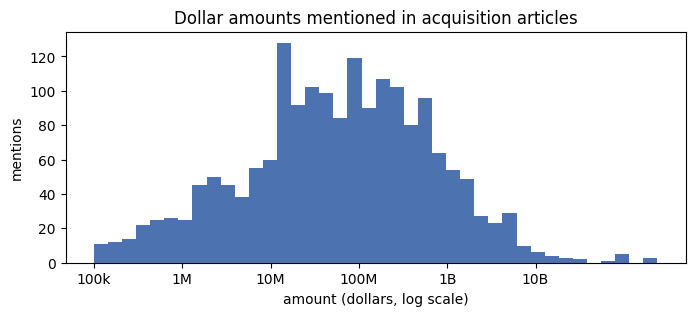

In [21]:
SCALE = {"mln": 1e6, "billion": 1e9, "bln": 1e9, None: 1.0}

def money_values(text):
    out = []
    for amount, scale, currency in MONEY.findall(text):
        cur = currency.lower().rstrip("s") if currency.lower().startswith("dlr") else currency.lower()
        out.append((float(amount.replace(",", "")) * SCALE[scale.lower() if scale else None], cur))
    return out

acq = df[df["topics"].apply(lambda ts: "acq" in ts)]
usd = [v for t in acq["text"] for v, cur in money_values(t) if cur == "dlr" and v >= 1e5]
print(f"{len(usd):,} dollar amounts >= 100,000 in {len(acq):,} acquisition articles; "
      f"median {np.median(usd) / 1e6:,.0f} mln dlrs, largest {max(usd) / 1e9:,.1f} billion dlrs")
plt.figure(figsize=(8, 3))
plt.hist(np.log10(usd), bins=40, color="#4C72B0")
plt.xticks([5, 6, 7, 8, 9, 10], ["100k", "1M", "10M", "100M", "1B", "10B"])
plt.xlabel("amount (dollars, log scale)"); plt.ylabel("mentions")
plt.title("Dollar amounts mentioned in acquisition articles");

The distribution centres on tens of millions of dollars, but the largest values are not deal prices: they are figures such as the U.S.  trade deficit or a bank's total assets quoted inside acquisition stories. 
Extraction gives *mentions*, deciding which mention is "the price paid" is a relation-extraction problem, a step beyond NER.

## 4b. Linking tickers to companies

The bracket convention also gives entity linking for free: the capitalised words right before `<TICKER>` name the company. 
Only article **bodies** are used: in all-caps headlines every word is capitalised, so the pattern cannot tell where a name starts ("MOODY'S UPGRADES GE <GE>" would yield the name "MOODY'S UPGRADES GE").

In [22]:
NAME_BEFORE_TICKER = re.compile(r"((?:[A-Z][A-Za-z&.'\-]*\s+){1,6})<([A-Z][A-Z0-9.]{0,5})>")
LEADING_NOISE = re.compile(r"^(?:SAID|SAYS|THE|AND|OF|TO|IN|BY|FOR)\s+")

names_by_ticker = defaultdict(Counter)
for text in df["body"]:
    for name, ticker in NAME_BEFORE_TICKER.findall(text):
        name = re.sub(r"\s+", " ", name).strip().upper()
        name = re.sub(r"'S$", "", LEADING_NOISE.sub("", name))
        names_by_ticker[ticker][name] += 1

ticker_mentions = Counter(t for text in df["text"] for t in TICKER.findall(text))
print(f"{len(names_by_ticker):,} distinct tickers linked to at least one name")
pd.DataFrame([{"ticker": t, "mentions": n, "surface forms": ", ".join(f"{name} ({c})" for name, c in names_by_ticker[t].most_common(4))} for t, n in ticker_mentions.most_common(10)])

1,309 distinct tickers linked to at least one name


,ticker,mentions,surface forms
0,GM,100,"GENERAL MOTORS CORP (28), GENERAL MOTOR CORP (2), GENERAL MOTORS CORP. (1), GENERAL MOTORS (1)"
1,C,90,"CHRYSLER CORP (31), NOW CHRYSLER CORP (1), CHRYSLER MOTORS CORP (1), CHRYSLER (1)"
2,F,83,"FORD MOTOR CO (39), FORD MOTOR CREDIT CO (2), FORD MOTOR CO. (1), FORD CO (1)"
3,IBM,73,"INTERNATIONAL BUSINESS MACHINES CORP (35), INTERNATIONAL BUSINESS MACHINES (3), INTERNATIONAL BU..."
4,GE,67,"GENERAL ELECTRIC CO (27), GENERAL ELECTRIC (3), GENERAL ELECTRICS CO (1), GENERAL ELECTRIC CREDI..."
5,T,52,"TELEGRAPH CO (16), ATT (2), TELEGRAPH (1), TRANSCO ENERGY CO (1)"
6,TX,51,"TEXACO INC (20), TEXACO (1), TEXACO INC. (1)"
7,BA,50,"BOEING CO (28), BOEING CO. (2)"
8,MER,46,"CO INC (22), CO (5), MERRILL LYNCH CAPITAL MARKETS (2), SMITH INC (1)"
9,CCI,46,"CITICORP (32), YESTERDAY CITICORP (2), U.S. BANK CITICORP (1)"


Every frequent company appears under several surface forms (possessives, with or without "Co", subsidiaries such as "Ford Motor Credit Co"). 
That is the entity-linking problem in miniature, and the ticker acts as a free canonical identifier. 
Details only visible in the data:
- ticker `C` is **Chrysler** in 1987 (Citicorp is `CCI`): tickers are reassigned over time, so a ticker identifies a company only *at a given date*
- AT&T comes out as `TELEGRAPH CO` and Merrill Lynch as `CO INC`: the pattern stops at the lower-case "and" in "American Telephone and Telegraph Co" and "Merrill Lynch and Co Inc"
- sentence-initial words leak in ("NOW CHRYSLER CORP")

Simple rules get most of the way, the remaining errors are exactly the cases that justify a learned model or a reference list of company names.

## 4c. Company co-mention network

Companies mentioned in the same acquisition article (by ticker) are linked: edge weight = number of articles.

In [23]:
graph = nx.Graph()
for text in acq["text"]:
    tickers = sorted(set(TICKER.findall(text)))
    for a, b in combinations(tickers, 2):
        w = graph[a][b]["weight"] + 1 if graph.has_edge(a, b) else 1
        graph.add_edge(a, b, weight=w)

def label(t):
    return names_by_ticker[t].most_common(1)[0][0].title() if names_by_ticker[t] else t

top_edges = sorted(graph.edges(data="weight"), key=lambda e: -e[2])[:12]
pd.DataFrame([{"company A": label(a), "company B": label(b), "articles together": w} for a, b, w in top_edges])

,company A,company B,articles together
0,Piedmont Aviation Inc,Usair Group,18
1,Usair Group,Trans World Airlines Inc,18
2,Chrysler Corp,American Motors Corp,14
3,Chemlawn Corp,Waste Management Inc,10
4,Piedmont Aviation Inc,Trans World Airlines Inc,10
5,Gencorp Inc,Afg Industries Inc,10
6,Baker International Corp,Hughes Tool Co,9
7,Video Affiliates Inc,Cyclops Corp,9
8,Standard Oil Co,British Petroleum Co Plc,9
9,Borg-Warner Corp,Gaf Corp,8


48 companies, 19 separate clusters, sizes [4, 4, 4, 2, 3, 3, 3, 2, 3, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2]


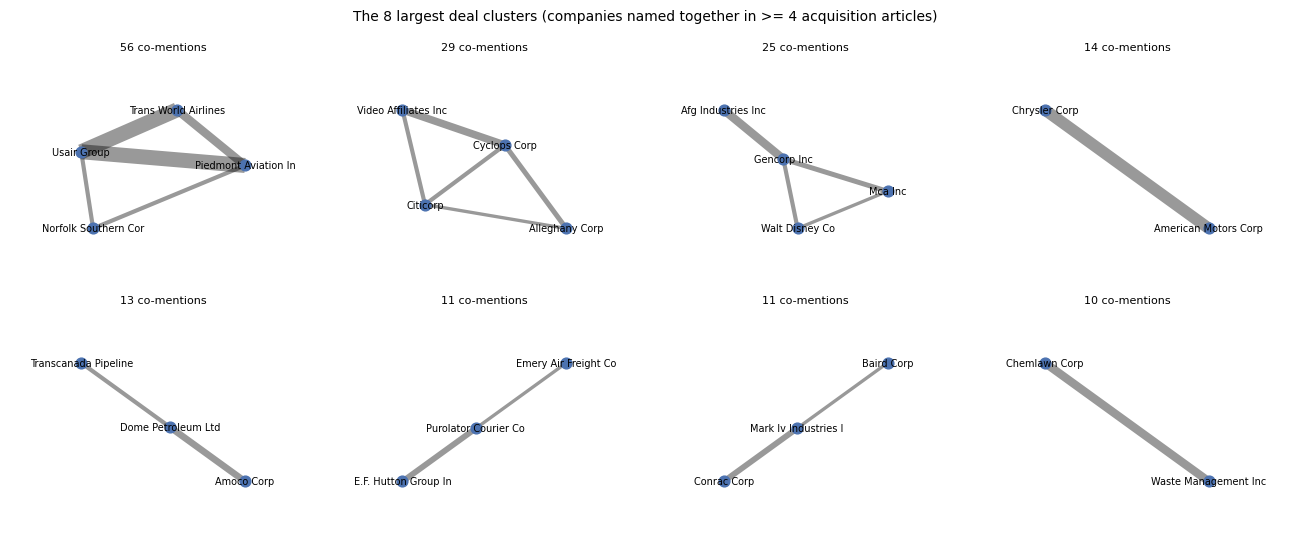

In [24]:
MIN_ARTICLES = 4   # keep pairs named together in at least this many articles
strong = nx.Graph([(a, b, d) for a, b, d in graph.edges(data=True) if d["weight"] >= MIN_ARTICLES])
clusters = sorted(nx.connected_components(strong), key=lambda c: -strong.subgraph(c).size(weight="weight"))
print(f"{strong.number_of_nodes()} companies, {len(clusters)} separate clusters, sizes {[len(c) for c in clusters]}")

fig, axes = plt.subplots(2, 4, figsize=(13, 5.5))
for ax, cluster in zip(axes.ravel(), clusters):
    sub = strong.subgraph(cluster)
    pos = nx.spring_layout(sub, seed=RANDOM_STATE, k=1.5 / np.sqrt(len(sub)), iterations=300)
    nx.draw_networkx_edges(sub, pos, ax=ax, width=[0.6 * sub[a][b]["weight"] for a, b in sub.edges], alpha=0.4)
    nx.draw_networkx_nodes(sub, pos, ax=ax, node_size=60, node_color="#4C72B0")
    nx.draw_networkx_labels(sub, pos, ax=ax, labels={n: label(n)[:20] for n in sub}, font_size=7)
    ax.set_title(f"{int(sub.size(weight='weight'))} co-mentions", fontsize=8)
    ax.margins(0.35); ax.axis("off")
plt.suptitle(f"The 8 largest deal clusters (companies named together in >= {MIN_ARTICLES} acquisition articles)", fontsize=10)
plt.tight_layout();

Keeping only strong links breaks the graph into many small, separate clusters: **each cluster is one takeover story**. 
The strongest are the big deals of 1987: USAir acquiring Piedmont while TWA bid for USAir, Chrysler buying American Motors, BP buying out Standard Oil, Waste Management's bid for ChemLawn, the Baker / Hughes Tool merger, GenCorp defending against AFG. Without any model, ticker co-occurrence alone recovers the deal landscape.

Two limits: errors of the linking rule carry over into the labels (a company the rule cuts short, like Merrill Lynch's "Co Inc", would appear under that wrong name), and companies quoted without a ticker are invisible here.

## 4d. Statistical NER with spaCy (optional)

A pretrained model finds entities with no corpus convention, including companies without a ticker. 
Its main weakness here is predicted by section 1: almost every headline is in capitals.

In [25]:
import spacy
nlp = spacy.load("en_core_web_sm")

def ents(text):
    return [(e.text, e.label_) for e in nlp(text).ents]

headline = "CHRYSLER CORP TO BUY AMERICAN MOTORS FOR 1.5 BILLION DLRS"
print("as written: ", ents(headline))
print("title case: ", ents(headline.title()))
print("lower case: ", ents(headline.lower()))

as written:  [('CHRYSLER CORP TO', 'ORG'), ('BUY AMERICAN MOTORS', 'ORG'), ('1.5 BILLION', 'MONEY')]
title case:  [('Chrysler Corp', 'ORG'), ('Buy American Motors', 'ORG'), ('1.5 Billion', 'CARDINAL')]
lower case:  [('chrysler corp to', 'ORG'), ('american motors', 'ORG'), ('1.5 billion', 'CARDINAL')]


In [26]:
# Agreement between spaCy ORG and the ticker-linked names, on acquisition article bodies
sample = acq.sample(200, random_state=RANDOM_STATE)
found = linked = 0
for text in sample["body"]:
    orgs = {e.text.upper() for e in nlp(text).ents if e.label_ == "ORG"}
    for name, _ in NAME_BEFORE_TICKER.findall(text):
        linked += 1
        found += any(o in name.upper() or name.strip().upper() in o for o in orgs)
print(f"ticker-linked company names also tagged ORG by spaCy: {found / max(1, linked):.1%} of {linked}")

ticker-linked company names also tagged ORG by spaCy: 95.5% of 88


In [27]:
TARGET_ENTITY_TYPES = ['ORG', 'PERSON', 'MONEY']

# Apply NER to all documents
def extract_entities(texts):
    entities = []
    for doc in nlp.pipe(texts, batch_size=32, disable=["tagger", "parser"]):
        entities.extend([(ent.text, ent.label_) for ent in doc.ents if ent.label_ in TARGET_ENTITY_TYPES])
    return entities

all_entities = extract_entities(df['text'].tolist())

# Convert to DataFrame for analysis
entities_df = pd.DataFrame(all_entities, columns=['entity', 'label'])

# Count entities by type
entity_counts = entities_df['label'].value_counts()
print("Top entity types (ORG, PERSON, MONEY):\n", entity_counts)

# Optional: top 10 entities per type
top_entities_per_type = entities_df.groupby('label')['entity'].apply(lambda x: x.value_counts().head(10))
print("\nTop entities per type:\n")
top_entities_per_type

/Users/tomcuel/.venvs/global_env/lib/python3.11/site-packages/spacy/pipeline/lemmatizer.py:188: UserWarning: [W108] The rule-based lemmatizer did not find POS annotation for one or more tokens. Check that your pipeline includes components that assign token.pos, typically 'tagger'+'attribute_ruler' or 'morphologizer'.
  warnings.warn(Warnings.W108)


Top entity types (ORG, PERSON, MONEY):
 label
ORG       98760
PERSON    28722
MONEY      8832
Name: count, dtype: int64

Top entities per type:



label                    
MONEY   one cent               37
        150 yen                34
        three billion          29
        five billion           28
        one mln yen            23
        one billion            22
        15 billion yen         21
        140 yen                19
        seven billion          17
        0.50 cent              16
ORG     cts                  6199
        EC                   1349
        Reuters               991
        Treasury              633
        OPEC                  544
        Fed                   539
        Congress              529
        Bundesbank            459
        USDA                  450
        SEC                   437
PERSON  Reagan               1052
        Avg                   662
        Baker                 435
        Revs                  210
        James Baker           208
        Lawson                183
        Yeutter               129
        Funaro                126
        U.S. Dlrs     

# Takeaways

- **Financial wire text is not generic text**: dense abbreviations ("mln", "dlrs", "pct"), a high share of digits in earnings stories, and upper-case headlines. 
  Each one weakens general-purpose tools.
- **Word-based sentiment fails on earnings articles**, and the reason is structural: the direction lives in a comparison between two numbers. 
  A finance word list is near chance, a trained bag-of-words model does better but stays far below a short, exact parser. Sentiment models belong on narrative text.
- **Corpus conventions are the most reliable NER**: angle-bracket tickers, `mln dlrs`, `pct`. 
  They also give entity linking almost for free, and expose its real difficulties (name variants, reassigned tickers).
- **Statistical NER** adds coverage beyond conventions, at the cost of sensitivity to casing and no link to a canonical identifier.